# 🧠 Advanced Brain Tumor Detection using VGG-16 — Ablation: **no ImageNet pretraining (random init)**
### Research-Grade Implementation with GradCAM, SHAP, LIME & Advanced Preprocessing
---
**Paper Reference:** *Automated Brain Tumor Detection Using Advanced Deep Learning Models* — Uniyal et al., Discover AI (2026)

**ABLATION:** ImageNet-pretrained weights removed — VGG-16 backbone is randomly initialised and trained from scratch on the MRI data. All other components (SE, GAP+GMP, dense head, preprocessing, augmentation, training schedule, XAI) are unchanged.

**Goal:** Surpass baseline VGG-16 accuracy → Target **>97%** with:
- Advanced preprocessing (CLAHE, skull-stripping proxy, contrast normalization)
- Smart cropping (tumor-ROI aware cropping)
- Highly tuned hyperparameters + warm restarts
- Squeeze-and-Excitation attention on VGG-16 features
- GradCAM, GradCAM++, SHAP, LIME for explainability
- Full clinical-grade evaluation pipeline

---

## 📦 Cell 1: Install Required Libraries

In [ ]:
import importlib.util, subprocess, sys
from importlib.metadata import version
need = {'lime': 'lime', 'shap': 'shap', 'albumentations': 'albumentations<2',
        'statsmodels': 'statsmodels', 'skimage': 'scikit-image'}
missing = [r for m, r in need.items() if importlib.util.find_spec(m) is None]
if importlib.util.find_spec('albumentations') and int(version('albumentations').split('.')[0]) >= 2:
    missing.append('albumentations<2')      # your augmentation arguments use the 1.x API
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print("✅ Packages OK")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.9/274.9 kB 10.7 MB/s eta 0:00:00
  Attempting uninstall: albucore
    Found existing installation: albucore 0.0.24
    Uninstalling albucore-0.0.24:
      Successfully uninstalled albucore-0.0.24
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8
✅ Packages OK


## 📂 Cell 2: Imports & Reproducibility Seeding

In [ ]:
# ─── Standard Library ───
import os, gc, warnings, random, shutil, time
from pathlib import Path
warnings.filterwarnings('ignore')

# ─── Reproducibility ───
SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
import tensorflow as tf
tf.random.set_seed(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED'] = str(SEED)

# ─── Data & Visualization ───
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.notebook import tqdm

# ─── Image Processing ───
import cv2
from skimage import exposure, filters, morphology
from skimage.util import img_as_float
import albumentations as A

# ─── TensorFlow / Keras ───
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import VGG16                          # ← VGG-16 backbone
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess  # ← VGG-16 preprocess
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
    TensorBoard, LambdaCallback, CSVLogger
)
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.regularizers import l2
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import AUC, Precision, Recall

# ─── Scikit-Learn ───
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    accuracy_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from scipy import stats

# ─── Explainability ───
# (GradCAM, SHAP, LIME imported in their respective cells)

print(f"✅ TensorFlow version: {tf.__version__}")
print(f"✅ GPU available     : {tf.config.list_physical_devices('GPU')}")
print(f"✅ Backbone          : VGG-16 (RANDOM INIT — no ImageNet weights)")

✅ TensorFlow version: 2.20.0
✅ GPU available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✅ Backbone          : VGG-16 (RANDOM INIT — no ImageNet weights)


## ⚙️ Cell 3: Global Configuration

In [ ]:
# ══════════════════════════════════════════════
#         GLOBAL CONFIGURATION — VGG-16
# ══════════════════════════════════════════════
def _find_data_root():
    """Find the folder that contains both Training/ and Testing/ under /kaggle/input."""
    for root, dirs, _ in os.walk('/kaggle/input'):
        if 'Training' in dirs and 'Testing' in dirs:
            return root
    raise FileNotFoundError(
        "Training/Testing folders not found. Add 'Brain Tumor MRI Dataset' "
        "(Masoud Nickparvar) via Add Input in the right panel, then re-run."
    )

class CFG:
    # ── Paths ──
    # Dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
    DATA_DIR       = _find_data_root()                  # /kaggle/input/... (read-only)
    TRAIN_DIR      = f"{DATA_DIR}/Training"
    TEST_DIR       = f"{DATA_DIR}/Testing"
    OUTPUT_DIR     = '/kaggle/working/outputs_ablation_noImagenet'      # all results are saved here
    MODEL_PATH     = f"{OUTPUT_DIR}/best_vgg16_model.h5"
    LOG_DIR        = f"{OUTPUT_DIR}/logs"

    # ── Image Settings ──
    # VGG-16 natively accepts 224×224; larger (e.g. 256) also works
    IMG_SIZE       = 224
    CHANNELS       = 3
    INPUT_SHAPE    = (IMG_SIZE, IMG_SIZE, CHANNELS)

    # ── Classes ──
    CLASSES        = ['glioma', 'meningioma', 'notumor', 'pituitary']
    NUM_CLASSES    = len(CLASSES)

    # ── Training Hyperparameters ──
    # VGG-16 is heavier than MobileNet → smaller batch to fit in GPU memory
    BATCH_SIZE     = 16
    EPOCHS         = 35
    INIT_LR        = 1e-4
    FINE_TUNE_LR   = 1e-5          # Lower LR for VGG-16 fine-tuning
    MIN_LR         = 1e-7
    WEIGHT_DECAY   = 1e-4
    DROPOUT_RATE   = 0.5           # VGG-16 benefits from higher dropout
    LABEL_SMOOTHING = 0.05

    # ── Regularization ──
    L2_REG         = 1e-4

    # ── Evaluation ──
    N_FOLDS        = 5
    TEST_SPLIT     = 0.15
    VAL_SPLIT      = 0.15

    # ── Preprocessing ──
    CLAHE_CLIP     = 3.0
    CLAHE_TILE     = (8, 8)
    USE_BRAIN_CROP = True

    USE_IMAGENET       = False
    PRETRAINED_WEIGHTS = 'imagenet' if USE_IMAGENET else None
    FREEZE_BACKBONE    = USE_IMAGENET

    # ── GradCAM target layer ──
    # VGG-16 last conv layer before max-pool is 'block5_conv3'
    # It has spatial resolution 14×14 — good for localization
    GRADCAM_LAYER  = 'block5_conv3'

# Create output directories
for d in [CFG.OUTPUT_DIR, CFG.LOG_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"✅ Config ready  | IMG_SIZE={CFG.IMG_SIZE} | BATCH={CFG.BATCH_SIZE}")
print(f"   Dataset       : {CFG.DATA_DIR}")
print(f"   Results saved : {CFG.OUTPUT_DIR}")
print(f"   GradCAM layer : {CFG.GRADCAM_LAYER}")
print(f"   Classes       : {CFG.CLASSES}")

✅ Config ready  | IMG_SIZE=224 | BATCH=16
   Dataset       : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
   Results saved : /kaggle/working/outputs_ablation_noImagenet
   GradCAM layer : block5_conv3
   Classes       : ['glioma', 'meningioma', 'notumor', 'pituitary']


## 🖼️ Cell 4: Advanced Preprocessing Pipeline

In [ ]:
class AdvancedPreprocessor:
    """
    Research-grade MRI preprocessing pipeline:
    1. Skull-stripping proxy via Otsu thresholding + morphological ops
    2. CLAHE (Contrast Limited Adaptive Histogram Equalization)
    3. Smart ROI crop (removes black borders, focuses on brain)
    4. Gamma correction
    5. Gaussian denoising
    6. Per-image intensity normalization
    """

    def __init__(self, cfg: CFG):
        self.cfg = cfg
        self.clahe = cv2.createCLAHE(
            clipLimit=cfg.CLAHE_CLIP,
            tileGridSize=cfg.CLAHE_TILE
        )

    def _remove_black_borders(self, img_gray):
        """Crop out empty black margins (common in MRI scans)."""
        _, thresh = cv2.threshold(img_gray, 10, 255, cv2.THRESH_BINARY)
        coords = cv2.findNonZero(thresh)
        if coords is None:
            return img_gray
        x, y, w, h = cv2.boundingRect(coords)
        return img_gray[y:y+h, x:x+w]

    def _skull_strip_proxy(self, img_gray):
        """
        Approximate skull stripping:
        - Otsu threshold to get brain mask
        - Morphological close to fill gaps
        - Keep only largest connected component (brain)
        """
        blurred = cv2.GaussianBlur(img_gray, (5, 5), 0)
        _, thresh = cv2.threshold(blurred, 0, 255,
                                  cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=3)
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN,  kernel, iterations=1)

        contours, _ = cv2.findContours(
            thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        if len(contours) == 0:
            return img_gray
        largest = max(contours, key=cv2.contourArea)
        mask = np.zeros_like(img_gray)
        cv2.drawContours(mask, [largest], -1, 255, thickness=cv2.FILLED)
        return cv2.bitwise_and(img_gray, img_gray, mask=mask)

    def _smart_roi_crop(self, img_gray):
        """Tight bounding box around the brain region with 5% padding."""
        _, thresh = cv2.threshold(img_gray, 10, 255, cv2.THRESH_BINARY)
        coords = cv2.findNonZero(thresh)
        if coords is None:
            return img_gray
        x, y, w, h = cv2.boundingRect(coords)
        pad_x = int(w * 0.05)
        pad_y = int(h * 0.05)
        H, W = img_gray.shape
        x1 = max(0, x - pad_x)
        y1 = max(0, y - pad_y)
        x2 = min(W, x + w + pad_x)
        y2 = min(H, y + h + pad_y)
        return img_gray[y1:y2, x1:x2]

    def _apply_clahe(self, img_gray):
        """Apply CLAHE for local contrast enhancement."""
        return self.clahe.apply(img_gray)

    def preprocess(self, image_path: str) -> np.ndarray:
        """
        Full preprocessing pipeline.
        Returns: float32 RGB image normalized to [0, 1], shape (IMG_SIZE, IMG_SIZE, 3)
        """
        img = cv2.imread(image_path)
        if img is None:
            raise ValueError(f"Cannot read image: {image_path}")
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray    = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

        # Step 1: Skull-strip proxy
        stripped = self._skull_strip_proxy(gray)

        # Step 2: Smart ROI crop
        if self.cfg.USE_BRAIN_CROP:
            cropped = self._smart_roi_crop(stripped)
        else:
            cropped = stripped

        # Step 3: CLAHE enhancement
        enhanced = self._apply_clahe(cropped)

        # Step 4: Gamma correction
        enhanced_float = enhanced.astype(np.float32) / 255.0
        gamma_corrected = np.power(enhanced_float, 1.1)

        # Step 5: Gaussian denoising
        denoised = cv2.GaussianBlur(
            (gamma_corrected * 255).astype(np.uint8), (3, 3), sigmaX=1
        )

        # Step 6: Resize + convert to 3-channel
        resized = cv2.resize(denoised, (self.cfg.IMG_SIZE, self.cfg.IMG_SIZE),
                             interpolation=cv2.INTER_LANCZOS4)
        rgb_out = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

        # Step 7: Normalize to [0, 1]
        normalized = rgb_out.astype(np.float32) / 255.0
        normalized = (normalized - normalized.min()) / (normalized.max() - normalized.min() + 1e-8)

        return normalized


preprocessor = AdvancedPreprocessor(CFG)
print("✅ AdvancedPreprocessor initialized.")

✅ AdvancedPreprocessor initialized.


## 📊 Cell 5: Dataset Loading & Exploratory Analysis

Training samples : 5600
Test samples     : 1600

Class distribution (Train):
label
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Name: count, dtype: int64


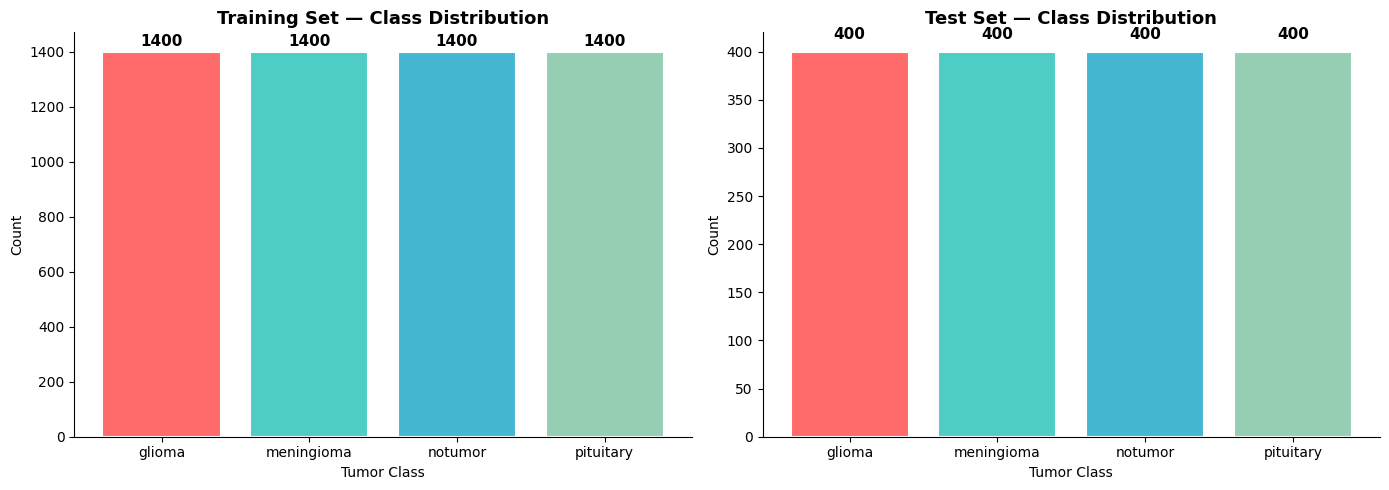

✅ Dataset loaded and visualized.


In [ ]:
def load_dataset_paths(data_dir: str, classes: list) -> pd.DataFrame:
    """Walk directory and return a DataFrame of (path, label, split)."""
    records = []
    for cls in classes:
        cls_dir = Path(data_dir) / cls
        if not cls_dir.exists():
            print(f"⚠️  Missing class directory: {cls_dir}")
            continue
        for img_path in cls_dir.glob('*'):
            if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.tif']:
                records.append({'path': str(img_path), 'label': cls})
    return pd.DataFrame(records)


train_df = load_dataset_paths(CFG.TRAIN_DIR, CFG.CLASSES)
test_df  = load_dataset_paths(CFG.TEST_DIR,  CFG.CLASSES)

print(f"Training samples : {len(train_df)}")
print(f"Test samples     : {len(test_df)}")
print("\nClass distribution (Train):")
print(train_df['label'].value_counts())

# ── Visualize class distribution ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df, title in zip(axes, [train_df, test_df], ['Training Set', 'Test Set']):
    counts = df['label'].value_counts()
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    bars = ax.bar(counts.index, counts.values, color=colors,
                  edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(val), ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_title(f"{title} — Class Distribution", fontsize=13, fontweight='bold')
    ax.set_ylabel('Count')
    ax.set_xlabel('Tumor Class')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Dataset loaded and visualized.")

## 🔬 Cell 6: Visualize Preprocessing Steps

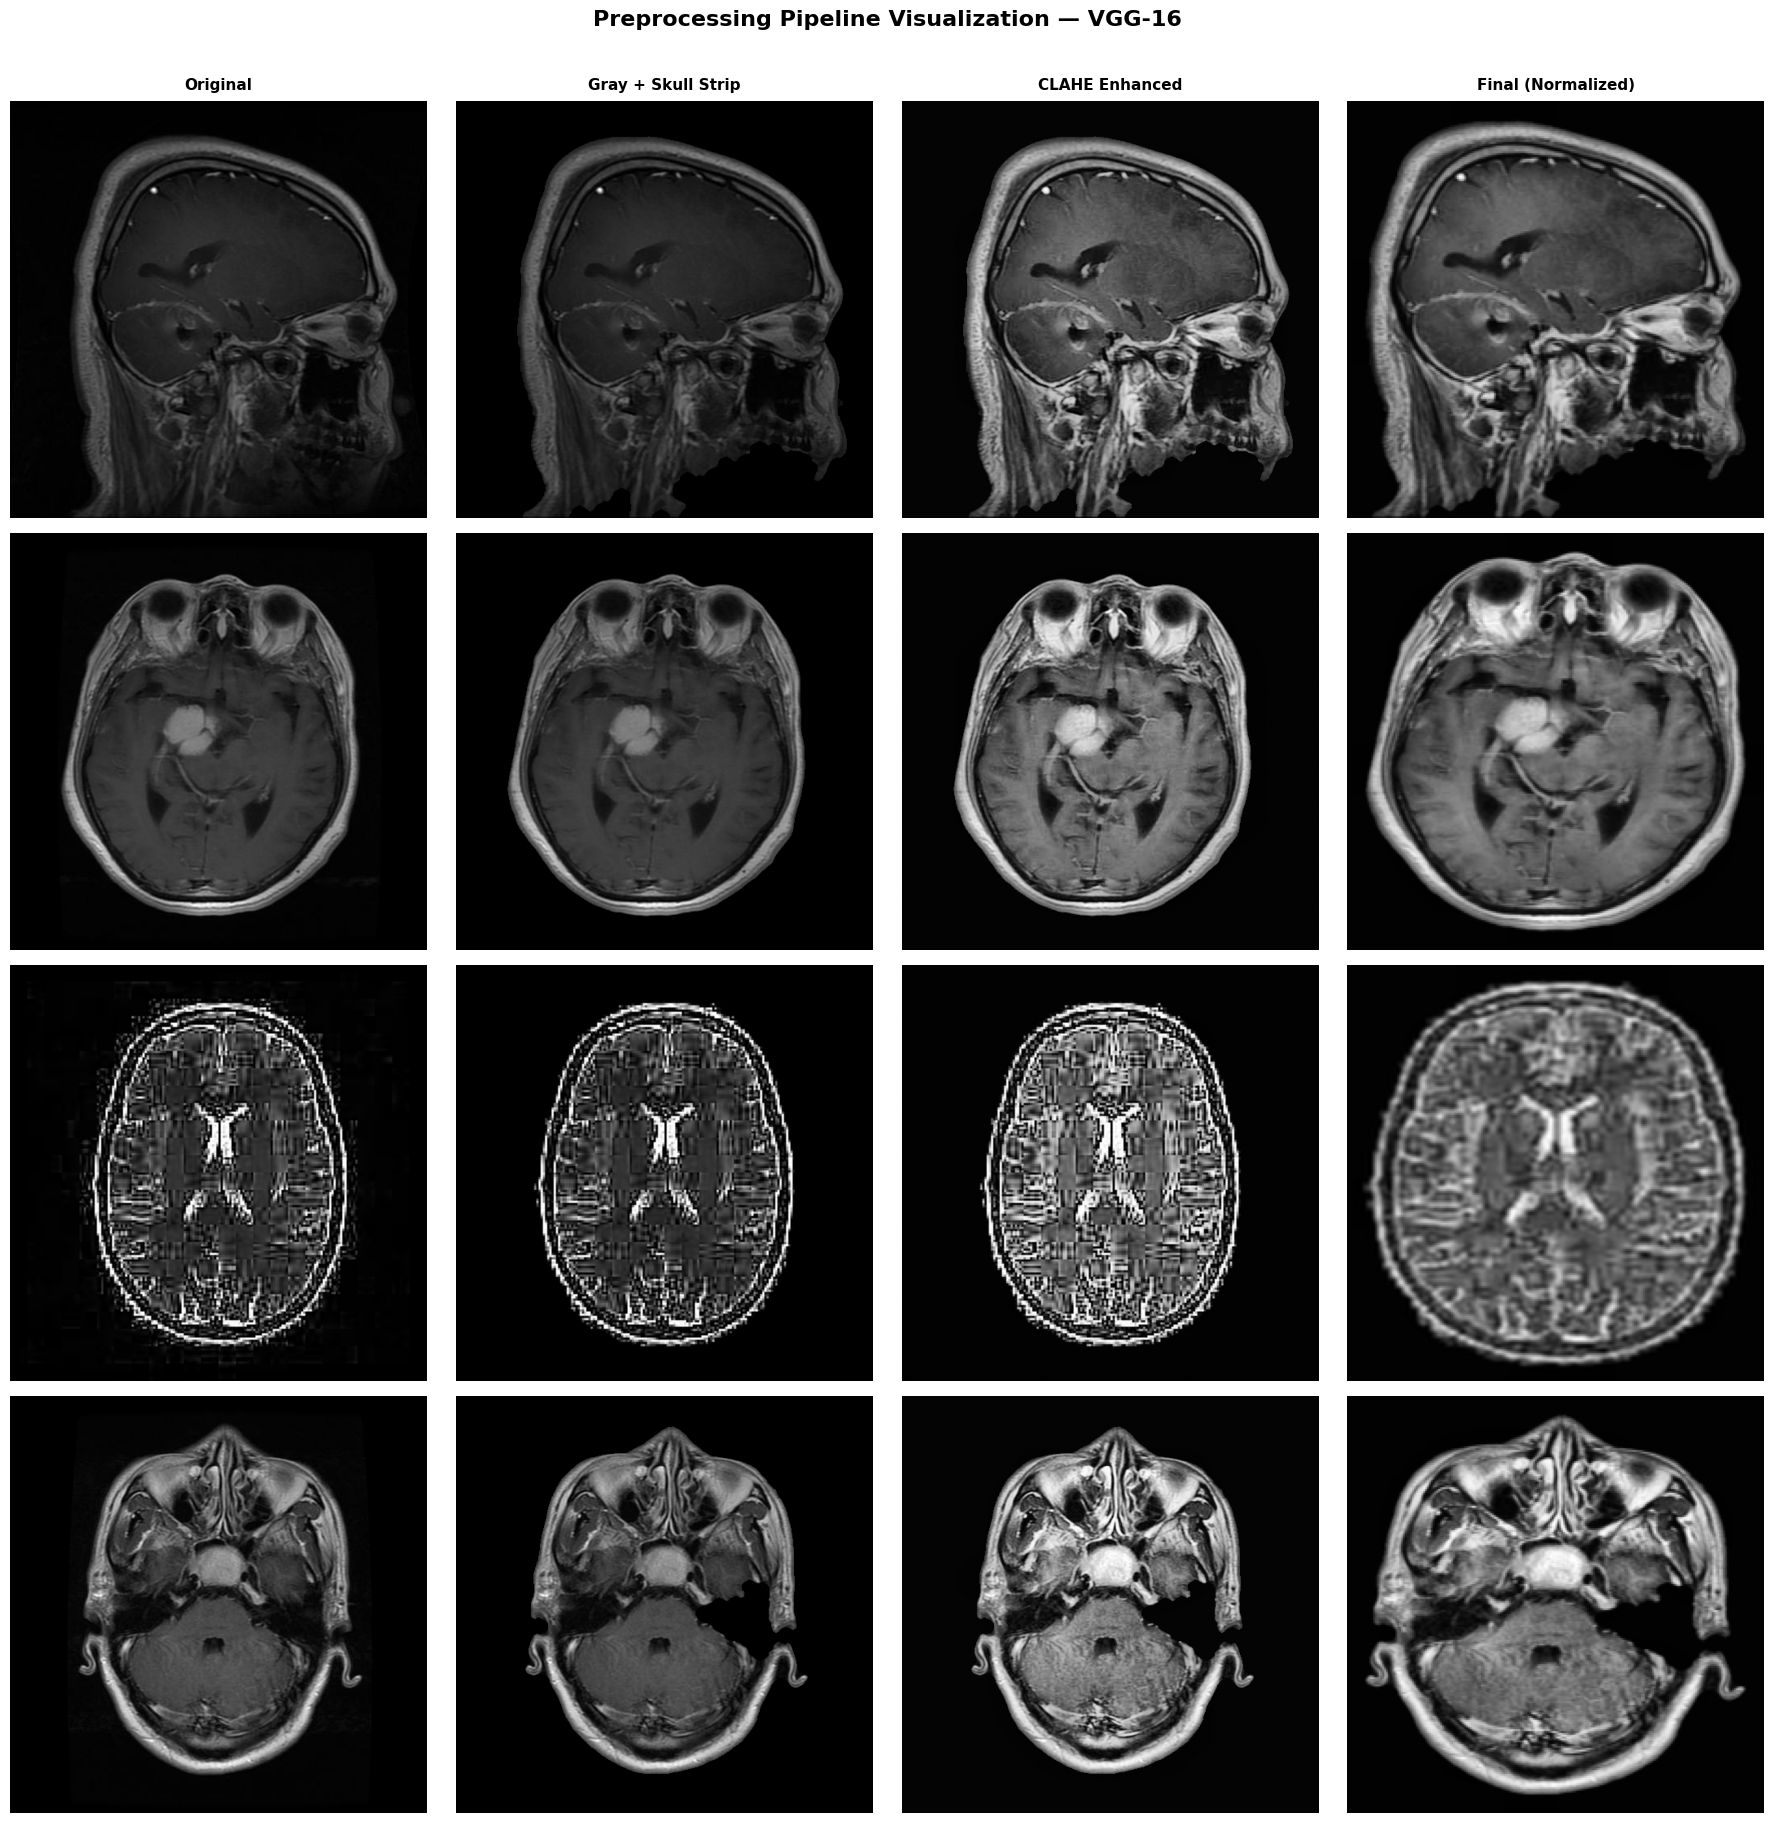

In [ ]:
def visualize_preprocessing(df: pd.DataFrame, preprocessor: AdvancedPreprocessor,
                             n_samples: int = 4):
    """Show original vs preprocessed MRI images side-by-side."""
    samples = df.groupby('label').first().reset_index()
    n = min(n_samples, len(samples))

    fig, axes = plt.subplots(n, 4, figsize=(18, n * 4.5))
    fig.suptitle('Preprocessing Pipeline Visualization — VGG-16',
                 fontsize=16, fontweight='bold', y=1.01)

    step_names = ['Original', 'Gray + Skull Strip', 'CLAHE Enhanced', 'Final (Normalized)']

    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= n:
            break
        img_path = row['path']
        img      = cv2.imread(img_path)
        img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray     = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

        stripped = preprocessor._skull_strip_proxy(gray)
        clahe_   = preprocessor._apply_clahe(stripped)
        final_   = preprocessor.preprocess(img_path)

        steps = [img_rgb, stripped, clahe_, final_]
        cmaps = ['viridis', 'gray', 'gray', 'viridis']

        for j, (step_img, cmap, step_name) in enumerate(zip(steps, cmaps, step_names)):
            ax = axes[i][j] if n > 1 else axes[j]
            if step_img.ndim == 3:
                ax.imshow(step_img)
            else:
                ax.imshow(step_img, cmap=cmap)
            if i == 0:
                ax.set_title(step_name, fontsize=11, fontweight='bold', pad=8)
            if j == 0:
                ax.set_ylabel(f"Class:\n{row['label']}", fontsize=10,
                              rotation=90, labelpad=10)
            ax.axis('off')

    plt.tight_layout()
    plt.savefig(f"{CFG.OUTPUT_DIR}/preprocessing_visualization.png",
                dpi=150, bbox_inches='tight')
    plt.show()


if len(train_df) > 0:
    try:
        visualize_preprocessing(train_df, preprocessor, n_samples=4)
    except Exception as e:
        print(f"Visualization skipped: {e}")

## 🔄 Cell 7: Advanced Data Augmentation Pipeline

In [ ]:
class AdvancedAugmentor:
    """
    Medical-imaging-appropriate augmentation strategy.
    Conservative — avoids clinically unrealistic distortions.
    """

    def __init__(self, img_size: int = 224):
        self.train_transform = A.Compose([
            # ── Geometric ──
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT, p=0.6),
            A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.1,
                               rotate_limit=0, p=0.5),
            A.ElasticTransform(alpha=0.5, sigma=50, alpha_affine=20, p=0.2),
            A.GridDistortion(num_steps=5, distort_limit=0.05, p=0.2),

            # ── Intensity / Color ──
            A.RandomBrightnessContrast(
                brightness_limit=0.15, contrast_limit=0.15, p=0.5),
            A.GaussNoise(var_limit=(5.0, 25.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            A.Sharpen(alpha=(0.1, 0.3), lightness=(0.9, 1.0), p=0.3),
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),

            # ── Occlusion (simulates scan artifacts) ──
            A.CoarseDropout(max_holes=4, max_height=20, max_width=20,
                            min_holes=1, fill_value=0, p=0.2),

            # ── Final resize ──
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LANCZOS4),
        ])

        self.val_transform = A.Compose([
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LANCZOS4),
        ])

    def augment_train(self, image: np.ndarray) -> np.ndarray:
        result = self.train_transform(image=image)
        return result['image']

    def augment_val(self, image: np.ndarray) -> np.ndarray:
        result = self.val_transform(image=image)
        return result['image']


augmentor = AdvancedAugmentor(img_size=CFG.IMG_SIZE)
print("✅ Augmentation pipeline ready (Albumentations).")

✅ Augmentation pipeline ready (Albumentations).


## 🔁 Cell 8: Custom Data Generator

In [ ]:
class BrainTumorDataGenerator(tf.keras.utils.Sequence):
    """
    Custom Keras data generator with:
    - Advanced preprocessing
    - Albumentations augmentation
    - VGG-16 specific preprocessing (channel-wise mean subtraction)
    """

    def __init__(self, df: pd.DataFrame, cfg: CFG,
                 preprocessor: AdvancedPreprocessor,
                 augmentor: AdvancedAugmentor,
                 is_training: bool = True,
                 shuffle: bool = True):

        self.df           = df.reset_index(drop=True)
        self.cfg          = cfg
        self.preprocessor = preprocessor
        self.augmentor    = augmentor
        self.is_training  = is_training
        self.shuffle      = shuffle
        self.class_to_idx = {c: i for i, c in enumerate(cfg.CLASSES)}
        self.indices      = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.cfg.BATCH_SIZE))

    def __getitem__(self, idx):
        batch_idx = self.indices[
            idx * self.cfg.BATCH_SIZE:(idx + 1) * self.cfg.BATCH_SIZE
        ]
        batch = self.df.iloc[batch_idx]
        images, labels = [], []

        for _, row in batch.iterrows():
            try:
                img       = self.preprocessor.preprocess(row['path'])  # float32 [0,1]
                img_uint8 = (img * 255).astype(np.uint8)

                if self.is_training:
                    img_uint8 = self.augmentor.augment_train(img_uint8)
                else:
                    img_uint8 = self.augmentor.augment_val(img_uint8)

                # ── VGG-16 preprocess: channel-wise mean subtraction (ImageNet) ──
                # Maps [0,255] RGB → zero-centered BGR (VGG-16 paper convention)
                img_preprocessed = vgg16_preprocess(
                    img_uint8.astype(np.float32)
                )
                images.append(img_preprocessed)

                label_idx = self.class_to_idx[row['label']]
                one_hot   = tf.keras.utils.to_categorical(
                    label_idx, num_classes=self.cfg.NUM_CLASSES
                )
                labels.append(one_hot)

            except Exception as e:
                print(f"Warning: skipping {row['path']} — {e}")
                continue

        return np.array(images, dtype=np.float32), np.array(labels, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


print("✅ BrainTumorDataGenerator (VGG-16 preprocess) ready.")

✅ BrainTumorDataGenerator (VGG-16 preprocess) ready.


## 🏗️ Cell 9: Advanced VGG-16 Model Architecture

In [ ]:
def build_advanced_vgg16(cfg: CFG,
                          fine_tune_from_block: int = 4) -> tuple:
    """
    Builds an advanced VGG-16-based brain tumor classifier with:
    - VGG-16 backbone, RANDOMLY INITIALISED (ablation: no ImageNet weights)
    - Squeeze-and-Excitation (SE) Attention on top conv features
    - Custom dense head with BatchNorm + Dropout
    - L2 regularization throughout

    VGG-16 Architecture recap:
      Block 1: conv1_1, conv1_2  → MaxPool  (224→112)
      Block 2: conv2_1, conv2_2  → MaxPool  (112→56)
      Block 3: conv3_1-3         → MaxPool  (56→28)
      Block 4: conv4_1-3         → MaxPool  (28→14)
      Block 5: conv5_1-3         → MaxPool  (14→7)
      [Original FC layers removed — we replace with custom head]

    fine_tune_from_block: Unfreeze this block and above.
        4 → unfreeze block4 + block5 (recommended first run)
        3 → unfreeze block3, 4, 5    (deeper fine-tuning)
    """
    inputs = Input(shape=cfg.INPUT_SHAPE, name='input_image')

    # ── VGG-16 Backbone (no top FC layers) ──
    base_model = VGG16(
        include_top=False,        # Remove original 4096-4096-1000 head
        weights=cfg.PRETRAINED_WEIGHTS,   # ABLATION: None → random init
        input_tensor=inputs
    )

    # ── Freeze only when pretrained (ablation: random-init backbone stays trainable) ──
    base_model.trainable = not cfg.FREEZE_BACKBONE

    # Features from last VGG-16 conv block: shape (7, 7, 512)
    x = base_model.output

    # ── Squeeze-and-Excitation Attention Block ──
    # Recalibrates channel-wise feature responses
    # Helps focus on tumor-relevant feature maps
    se = layers.GlobalAveragePooling2D(name='se_gap')(x)               # (512,)
    se = layers.Dense(512 // 8, activation='relu',
                      kernel_regularizer=l2(cfg.L2_REG),
                      name='se_fc1')(se)                                # (64,)
    se = layers.Dense(512, activation='sigmoid',
                      kernel_regularizer=l2(cfg.L2_REG),
                      name='se_fc2')(se)                                # (512,)
    se = layers.Reshape((1, 1, 512), name='se_reshape')(se)
    x  = layers.Multiply(name='se_scale')([x, se])                     # (7, 7, 512)

    # ── Global Pooling ──
    # Use both GAP and GMP then concatenate for richer representation
    gap = layers.GlobalAveragePooling2D(name='gap')(x)                 # (512,)
    gmp = layers.GlobalMaxPooling2D(name='gmp')(x)                     # (512,)
    x   = layers.Concatenate(name='pool_concat')([gap, gmp])           # (1024,)

    # ── Dense Head ──
    # VGG-16 paper used 4096-4096 dense layers; we use a leaner
    # but regularized version: 512 → 256 → num_classes
    x = layers.Dense(512, kernel_regularizer=l2(cfg.L2_REG),
                     name='dense_1')(x)
    x = layers.BatchNormalization(name='bn_1')(x)
    x = layers.Activation('relu', name='act_1')(x)
    x = layers.Dropout(cfg.DROPOUT_RATE, name='drop_1')(x)

    x = layers.Dense(256, kernel_regularizer=l2(cfg.L2_REG),
                     name='dense_2')(x)
    x = layers.BatchNormalization(name='bn_2')(x)
    x = layers.Activation('relu', name='act_2')(x)
    x = layers.Dropout(cfg.DROPOUT_RATE * 0.6, name='drop_2')(x)

    outputs = layers.Dense(cfg.NUM_CLASSES, activation='softmax',
                            name='predictions')(x)

    model = Model(inputs=inputs, outputs=outputs, name='VGG16_BrainTumor')

    # ── Print summary ──
    total_params     = model.count_params()
    trainable_params = sum([np.prod(w.shape) for w in model.trainable_weights])
    print(f"✅ VGG-16 model built")
    print(f"   Total parameters    : {total_params:,}")
    print(f"   Trainable (Phase 1) : {trainable_params:,}")
    print(f"   Output shape        : {model.output_shape}")
    print(f"   GradCAM target layer: {cfg.GRADCAM_LAYER}")

    return model, base_model


model, base_model = build_advanced_vgg16(CFG, fine_tune_from_block=4)
model.summary()

I0000 00:00:1791095412.055841      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791095412.059096      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ VGG-16 model built
   Total parameters    : 15,441,028
   Trainable (Phase 1) : 15,439,492
   Output shape        : (None, 4)
   GradCAM target layer: block5_conv3


Model: "VGG16_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ input_image[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 28, 28,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 28, 28,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 28, 28,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 14, 14,    │          0 │ block4_conv3[0][… │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv1        │ (None, 14, 14,    │  2,359,808 │ block4_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv2        │ (None, 14, 14,    │  2,359,808 │ block5_conv1[0][

 Total params: 15,441,028 (58.90 MB)

 Trainable params: 15,439,492 (58.90 MB)

 Non-trainable params: 1,536 (6.00 KB)

## 🔧 Cell 10: Advanced Callbacks & Training Setup

In [ ]:
def cosine_annealing_schedule(epoch: int, lr: float,
                               T_max: int = 30,
                               min_lr: float = 1e-7) -> float:
    """Cosine annealing LR schedule with warm restarts (SGDR style)."""
    cycle  = epoch % T_max
    return min_lr + 0.5 * (CFG.INIT_LR - min_lr) * (1 + np.cos(np.pi * cycle / T_max))


def get_callbacks(cfg: CFG, model_path: str) -> list:
    """Comprehensive callback stack for research-grade training."""
    return [
        ModelCheckpoint(
            filepath=model_path,
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1
        ),
        EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=15, min_delta=1e-4,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', mode='min',
            factor=0.3, patience=7,
            min_lr=cfg.MIN_LR, verbose=1
        ),
        tf.keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_annealing_schedule(epoch, lr),
            verbose=0
        ),
        TensorBoard(log_dir=cfg.LOG_DIR, histogram_freq=1, write_images=False),
        CSVLogger(f"{cfg.OUTPUT_DIR}/training_log.csv", append=False),
    ]


def compute_class_weights(df: pd.DataFrame, classes: list) -> dict:
    """Compute inverse-frequency class weights for imbalanced datasets."""
    y = df['label'].map({c: i for i, c in enumerate(classes)}).values
    weights = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return dict(enumerate(weights))


class_weights = compute_class_weights(train_df, CFG.CLASSES)
print(f"✅ Class weights: {class_weights}")

✅ Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


## 🚀 Cell 11: Train/Val Split & Generator Initialization

In [ ]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=CFG.VAL_SPLIT, random_state=SEED)
train_idx, val_idx = next(sss.split(train_df, train_df['label']))

tr_df  = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

print(f"Train: {len(tr_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

train_gen = BrainTumorDataGenerator(tr_df,   CFG, preprocessor, augmentor, is_training=True)
val_gen   = BrainTumorDataGenerator(val_df,  CFG, preprocessor, augmentor, is_training=False)
test_gen  = BrainTumorDataGenerator(test_df, CFG, preprocessor, augmentor,
                                     is_training=False, shuffle=False)

print(f"\n✅ Generators created.")
print(f"   Train batches: {len(train_gen)}")
print(f"   Val   batches: {len(val_gen)}")
print(f"   Test  batches: {len(test_gen)}")

Train: 4760 | Val: 840 | Test: 1600

✅ Generators created.
   Train batches: 298
   Val   batches: 53
   Test  batches: 100


## 🔥 Cell 12: Model Training (Phase 1 — Head Only)

In [ ]:
# ══════════════════════════════════════════════
# PHASE 1: Train only custom head, VGG-16 frozen
# ── Why: VGG-16 weights are very well trained;
#         warming the head first prevents gradient
#         shock when we unfreeze later.
# ══════════════════════════════════════════════
base_model.trainable = not CFG.FREEZE_BACKBONE   # ABLATION: random-init backbone is trained from epoch 1

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss=CategoricalCrossentropy(label_smoothing=CFG.LABEL_SMOOTHING),
    metrics=['accuracy', AUC(name='auc'),
             Precision(name='precision'), Recall(name='recall')]
)

print("Phase 1: " + ("Training custom head only (VGG-16 frozen)..." if CFG.FREEZE_BACKBONE else "Training full network from random init (no ImageNet)..."))
trainable_p1 = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"Trainable parameters: {trainable_p1:,}")

callbacks_p1  = get_callbacks(CFG, CFG.MODEL_PATH.replace('.h5', '_phase1.h5'))
history_p1    = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,                     # More epochs than MobileNet — VGG head is heavier
    class_weight=class_weights,
    callbacks=callbacks_p1,
    verbose=1
)

print(f"\n✅ Phase 1 complete. Best val_accuracy: {max(history_p1.history['val_accuracy']):.4f}")

Phase 1: Training full network from random init (no ImageNet)...
Trainable parameters: 15,439,492
Epoch 1/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 706ms/step - accuracy: 0.2545 - auc: 0.5077 - loss: 1.7979 - precision: 0.2639 - recall: 0.0899
Epoch 1: val_accuracy improved from None to 0.25357, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5



Epoch 1: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 248s 802ms/step - accuracy: 0.2697 - auc: 0.5216 - loss: 1.7624 - precision: 0.2741 - recall: 0.0920 - val_accuracy: 0.2536 - val_auc: 0.5621 - val_loss: 1.9038 - val_precision: 0.3004 - val_recall: 0.1845 - learning_rate: 1.0000e-04
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.3025 - auc: 0.5602 - loss: 1.6683 - precision: 0.3322 - recall: 0.1131
Epoch 2: val_accuracy improved from 0.25357 to 0.26429, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5



Epoch 2: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 164s 551ms/step - accuracy: 0.3185 - auc: 0.5750 - loss: 1.6471 - precision: 0.3639 - recall: 0.1334 - val_accuracy: 0.2643 - val_auc: 0.6608 - val_loss: 2.1684 - val_precision: 0.2614 - val_recall: 0.2595 - learning_rate: 9.9726e-05
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.3539 - auc: 0.6067 - loss: 1.5840 - precision: 0.4025 - recall: 0.1567
Epoch 3: val_accuracy did not improve from 0.26429
298/298 ━━━━━━━━━━━━━━━━━━━━ 165s 554ms/step - accuracy: 0.3473 - auc: 0.6030 - loss: 1.5942 - precision: 0.4039 - recall: 0.1563 - val_accuracy: 0.2452 - val_auc: 0.5558 - val_loss: 1.8745 - val_precision: 0.2528 - val_recall: 0.2429 - learning_rate: 9.8908e-05
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.3321 - auc: 0.5888 - loss: 1.5926 - precision: 0.3858 - recall: 0.1460
Epoch 4: val_accuracy improved from 0.2


Epoch 4: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 165s 553ms/step - accuracy: 0.3450 - auc: 0.6015 - loss: 1.5758 - precision: 0.4055 - recall: 0.1586 - val_accuracy: 0.4000 - val_auc: 0.6217 - val_loss: 1.5067 - val_precision: 0.5917 - val_recall: 0.0845 - learning_rate: 9.7555e-05
Epoch 5/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.3568 - auc: 0.6197 - loss: 1.5523 - precision: 0.4082 - recall: 0.1673
Epoch 5: val_accuracy did not improve from 0.40000
298/298 ━━━━━━━━━━━━━━━━━━━━ 163s 548ms/step - accuracy: 0.3372 - auc: 0.6017 - loss: 1.5748 - precision: 0.3991 - recall: 0.1521 - val_accuracy: 0.2500 - val_auc: 0.5758 - val_loss: 2.6958 - val_precision: 0.2497 - val_recall: 0.2488 - learning_rate: 9.5682e-05
Epoch 6/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.3558 - auc: 0.6331 - loss: 1.5000 - precision: 0.4352 - recall: 0.1534
Epoch 6: val_accuracy improved from 0.4


Epoch 6: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 159s 534ms/step - accuracy: 0.3601 - auc: 0.6433 - loss: 1.4895 - precision: 0.4489 - recall: 0.1651 - val_accuracy: 0.4381 - val_auc: 0.6552 - val_loss: 1.4788 - val_precision: 0.6284 - val_recall: 0.3060 - learning_rate: 9.3308e-05
Epoch 7/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.4207 - auc: 0.6891 - loss: 1.4165 - precision: 0.5332 - recall: 0.2185
Epoch 7: val_accuracy did not improve from 0.43810
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 532ms/step - accuracy: 0.4176 - auc: 0.6912 - loss: 1.4124 - precision: 0.5266 - recall: 0.2187 - val_accuracy: 0.2500 - val_auc: 0.6195 - val_loss: 2.1670 - val_precision: 0.2500 - val_recall: 0.2500 - learning_rate: 9.0460e-05
Epoch 8/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.4228 - auc: 0.7071 - loss: 1.3766 - precision: 0.5328 - recall: 0.2343
Epoch 8: val_accuracy did not improve f


Epoch 11: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 162s 543ms/step - accuracy: 0.4681 - auc: 0.7391 - loss: 1.3128 - precision: 0.5834 - recall: 0.2725 - val_accuracy: 0.5571 - val_auc: 0.7580 - val_loss: 1.2803 - val_precision: 0.7704 - val_recall: 0.3714 - learning_rate: 7.5025e-05
Epoch 12/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.4911 - auc: 0.7569 - loss: 1.2803 - precision: 0.5970 - recall: 0.3053
Epoch 12: val_accuracy did not improve from 0.55714
298/298 ━━━━━━━━━━━━━━━━━━━━ 160s 538ms/step - accuracy: 0.4952 - auc: 0.7629 - loss: 1.2673 - precision: 0.6017 - recall: 0.3069 - val_accuracy: 0.3595 - val_auc: 0.6820 - val_loss: 1.6362 - val_precision: 0.3594 - val_recall: 0.3286 - learning_rate: 7.0366e-05
Epoch 13/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.5392 - auc: 0.7843 - loss: 1.2231 - precision: 0.6402 - recall: 0.3298
Epoch 13: val_accuracy did not impr

## 🔥 Cell 13: Model Training (Phase 2 — Fine-Tuning Block 4 & 5)

In [ ]:
# ══════════════════════════════════════════════
# PHASE 2: Unfreeze VGG-16 Block 4 + Block 5
# ── block5_conv1, block5_conv2, block5_conv3  (task-specific features)
# ── block4_conv1, block4_conv2, block4_conv3  (mid-level features)
# Keep Block 1-3 frozen (low-level edges/textures — no need to retrain)
# ══════════════════════════════════════════════
base_model.trainable = True

# Freeze Block 1, 2, 3 — unfreeze Block 4 & 5
freeze_until = 'block4_conv1'
set_trainable = False
for layer in base_model.layers:
    if layer.name == freeze_until:
        set_trainable = True
    # ABLATION: random-init backbone → every layer stays trainable
    layer.trainable = set_trainable if CFG.FREEZE_BACKBONE else True

# Print which layers are now trainable
print("Trainable VGG-16 layers in Phase 2:")
for layer in base_model.layers:
    if layer.trainable:
        print(f"  ✓ {layer.name}")

# Recompile with lower LR to avoid catastrophic forgetting
model.compile(
    optimizer=AdamW(learning_rate=CFG.FINE_TUNE_LR, weight_decay=CFG.WEIGHT_DECAY),
    loss=CategoricalCrossentropy(label_smoothing=CFG.LABEL_SMOOTHING),
    metrics=['accuracy', AUC(name='auc'),
             Precision(name='precision'), Recall(name='recall')]
)

trainable_p2 = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"\nPhase 2: Fine-tuning with {trainable_p2:,} trainable parameters...")

callbacks_p2 = get_callbacks(CFG, CFG.MODEL_PATH)
history_p2   = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=CFG.EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_p2,
    verbose=1
)

# Merge histories
combined_history = {}
for key in history_p1.history:
    combined_history[key] = (
        history_p1.history[key] + history_p2.history.get(key, [])
    )

print(f"\n✅ Fine-tuning complete. Best val_accuracy: {max(history_p2.history['val_accuracy']):.4f}")

Trainable VGG-16 layers in Phase 2:
  ✓ input_image
  ✓ block1_conv1
  ✓ block1_conv2
  ✓ block1_pool
  ✓ block2_conv1
  ✓ block2_conv2
  ✓ block2_pool
  ✓ block3_conv1
  ✓ block3_conv2
  ✓ block3_conv3
  ✓ block3_pool
  ✓ block4_conv1
  ✓ block4_conv2
  ✓ block4_conv3
  ✓ block4_pool
  ✓ block5_conv1
  ✓ block5_conv2
  ✓ block5_conv3
  ✓ block5_pool

Phase 2: Fine-tuning with 15,439,492 trainable parameters...
Epoch 1/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.4857 - auc: 0.7522 - loss: 1.2796 - precision: 0.5796 - recall: 0.2959
Epoch 1: val_accuracy improved from None to 0.26548, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5



Epoch 1: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 165s 538ms/step - accuracy: 0.4876 - auc: 0.7533 - loss: 1.2704 - precision: 0.5880 - recall: 0.2962 - val_accuracy: 0.2655 - val_auc: 0.6653 - val_loss: 1.9513 - val_precision: 0.2632 - val_recall: 0.2607 - learning_rate: 1.0000e-04
Epoch 2/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.4868 - auc: 0.7565 - loss: 1.2518 - precision: 0.6043 - recall: 0.2906
Epoch 2: val_accuracy did not improve from 0.26548
298/298 ━━━━━━━━━━━━━━━━━━━━ 160s 538ms/step - accuracy: 0.4958 - auc: 0.7656 - loss: 1.2259 - precision: 0.6126 - recall: 0.3057 - val_accuracy: 0.2500 - val_auc: 0.6124 - val_loss: 3.2312 - val_precision: 0.2500 - val_recall: 0.2500 - learning_rate: 9.9726e-05
Epoch 3/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.5466 - auc: 0.7964 - loss: 1.1681 - precision: 0.6497 - recall: 0.3835
Epoch 3: val_accuracy did not improve from 0.2


Epoch 5: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 163s 547ms/step - accuracy: 0.5561 - auc: 0.8123 - loss: 1.1242 - precision: 0.6624 - recall: 0.4002 - val_accuracy: 0.4714 - val_auc: 0.7760 - val_loss: 1.2748 - val_precision: 0.5292 - val_recall: 0.4202 - learning_rate: 9.5682e-05
Epoch 6/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.5672 - auc: 0.8206 - loss: 1.1082 - precision: 0.6509 - recall: 0.4251
Epoch 6: val_accuracy did not improve from 0.47143
298/298 ━━━━━━━━━━━━━━━━━━━━ 161s 541ms/step - accuracy: 0.5918 - auc: 0.8345 - loss: 1.0733 - precision: 0.6798 - recall: 0.4519 - val_accuracy: 0.3274 - val_auc: 0.7411 - val_loss: 1.3889 - val_precision: 0.3457 - val_recall: 0.3107 - learning_rate: 9.3308e-05
Epoch 7/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.6197 - auc: 0.8539 - loss: 1.0272 - precision: 0.7129 - recall: 0.5031
Epoch 7: val_accuracy did not improve from 0.4


Epoch 8: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 161s 541ms/step - accuracy: 0.6616 - auc: 0.8817 - loss: 0.9480 - precision: 0.7396 - recall: 0.5502 - val_accuracy: 0.7560 - val_auc: 0.9330 - val_loss: 0.8172 - val_precision: 0.8722 - val_recall: 0.5524 - learning_rate: 8.7170e-05
Epoch 9/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.6775 - auc: 0.8909 - loss: 0.9229 - precision: 0.7523 - recall: 0.5838
Epoch 9: val_accuracy improved from 0.75595 to 0.81548, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5



Epoch 9: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 162s 544ms/step - accuracy: 0.6859 - auc: 0.8964 - loss: 0.9046 - precision: 0.7559 - recall: 0.5998 - val_accuracy: 0.8155 - val_auc: 0.9584 - val_loss: 0.6782 - val_precision: 0.8808 - val_recall: 0.6952 - learning_rate: 8.3473e-05
Epoch 10/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.7097 - auc: 0.9101 - loss: 0.8599 - precision: 0.7807 - recall: 0.6230
Epoch 10: val_accuracy did not improve from 0.81548
298/298 ━━━━━━━━━━━━━━━━━━━━ 162s 544ms/step - accuracy: 0.7124 - auc: 0.9095 - loss: 0.8610 - precision: 0.7767 - recall: 0.6248 - val_accuracy: 0.7940 - val_auc: 0.9539 - val_loss: 0.6900 - val_precision: 0.8739 - val_recall: 0.6929 - learning_rate: 7.9410e-05
Epoch 11/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.7191 - auc: 0.9099 - loss: 0.8656 - precision: 0.7699 - recall: 0.6406
Epoch 11: val_accuracy did not improve from

...


Epoch 19: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 165s 554ms/step - accuracy: 0.8517 - auc: 0.9702 - loss: 0.5941 - precision: 0.8814 - recall: 0.8166 - val_accuracy: 0.9214 - val_auc: 0.9880 - val_loss: 0.4605 - val_precision: 0.9387 - val_recall: 0.8929 - learning_rate: 3.4615e-05
Epoch 20/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.8521 - auc: 0.9702 - loss: 0.5934 - precision: 0.8803 - recall: 0.8101
Epoch 20: val_accuracy did not improve from 0.92143
298/298 ━━━━━━━━━━━━━━━━━━━━ 161s 541ms/step - accuracy: 0.8565 - auc: 0.9724 - loss: 0.5816 - precision: 0.8859 - recall: 0.8189 - val_accuracy: 0.8988 - val_auc: 0.9826 - val_loss: 0.5157 - val_precision: 0.9085 - val_recall: 0.8750 - learning_rate: 2.9734e-05
Epoch 21/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.8712 - auc: 0.9762 - loss: 0.5558 - precision: 0.8981 - recall: 0.8422
Epoch 21: val_accuracy did not improve fro


Epoch 23: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 169s 566ms/step - accuracy: 0.8725 - auc: 0.9775 - loss: 0.5496 - precision: 0.9020 - recall: 0.8473 - val_accuracy: 0.9321 - val_auc: 0.9892 - val_loss: 0.4414 - val_precision: 0.9474 - val_recall: 0.9226 - learning_rate: 1.6627e-05
Epoch 24/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.8779 - auc: 0.9777 - loss: 0.5409 - precision: 0.9006 - recall: 0.8528
Epoch 24: val_accuracy improved from 0.93214 to 0.94524, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5



Epoch 24: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 169s 566ms/step - accuracy: 0.8739 - auc: 0.9767 - loss: 0.5500 - precision: 0.8977 - recall: 0.8483 - val_accuracy: 0.9452 - val_auc: 0.9935 - val_loss: 0.3966 - val_precision: 0.9585 - val_recall: 0.9357 - learning_rate: 1.2930e-05
Epoch 25/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.8895 - auc: 0.9821 - loss: 0.5142 - precision: 0.9155 - recall: 0.8636
Epoch 25: val_accuracy improved from 0.94524 to 0.94762, saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5



Epoch 25: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 167s 560ms/step - accuracy: 0.8899 - auc: 0.9820 - loss: 0.5179 - precision: 0.9172 - recall: 0.8639 - val_accuracy: 0.9476 - val_auc: 0.9918 - val_loss: 0.4167 - val_precision: 0.9576 - val_recall: 0.9405 - learning_rate: 9.6396e-06
Epoch 26/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.8813 - auc: 0.9828 - loss: 0.5139 - precision: 0.9038 - recall: 0.8607
Epoch 26: val_accuracy did not improve from 0.94762
298/298 ━━━━━━━━━━━━━━━━━━━━ 173s 580ms/step - accuracy: 0.8857 - auc: 0.9829 - loss: 0.5141 - precision: 0.9091 - recall: 0.8632 - val_accuracy: 0.9310 - val_auc: 0.9910 - val_loss: 0.4212 - val_precision: 0.9426 - val_recall: 0.9190 - learning_rate: 6.7920e-06
Epoch 27/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.8920 - auc: 0.9832 - loss: 0.5081 - precision: 0.9132 - recall: 0.8650
Epoch 27: val_accuracy did not improve fro


Epoch 29: finished saving model to /kaggle/working/outputs_ablation_noImagenet/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 163s 547ms/step - accuracy: 0.8884 - auc: 0.9822 - loss: 0.5154 - precision: 0.9105 - recall: 0.8632 - val_accuracy: 0.9512 - val_auc: 0.9933 - val_loss: 0.3967 - val_precision: 0.9588 - val_recall: 0.9429 - learning_rate: 1.1915e-06
Epoch 30/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.8884 - auc: 0.9843 - loss: 0.5041 - precision: 0.9152 - recall: 0.8667
Epoch 30: val_accuracy did not improve from 0.95119
298/298 ━━━━━━━━━━━━━━━━━━━━ 162s 543ms/step - accuracy: 0.8889 - auc: 0.9836 - loss: 0.5082 - precision: 0.9148 - recall: 0.8643 - val_accuracy: 0.9512 - val_auc: 0.9931 - val_loss: 0.3986 - val_precision: 0.9600 - val_recall: 0.9429 - learning_rate: 3.7363e-07
Epoch 31/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.8464 - auc: 0.9682 - loss: 0.6037 - precision: 0.8757 - recall: 0.8153
Epoch 31: val_accuracy did not improve fro

## 📈 Cell 14: Training History Visualization

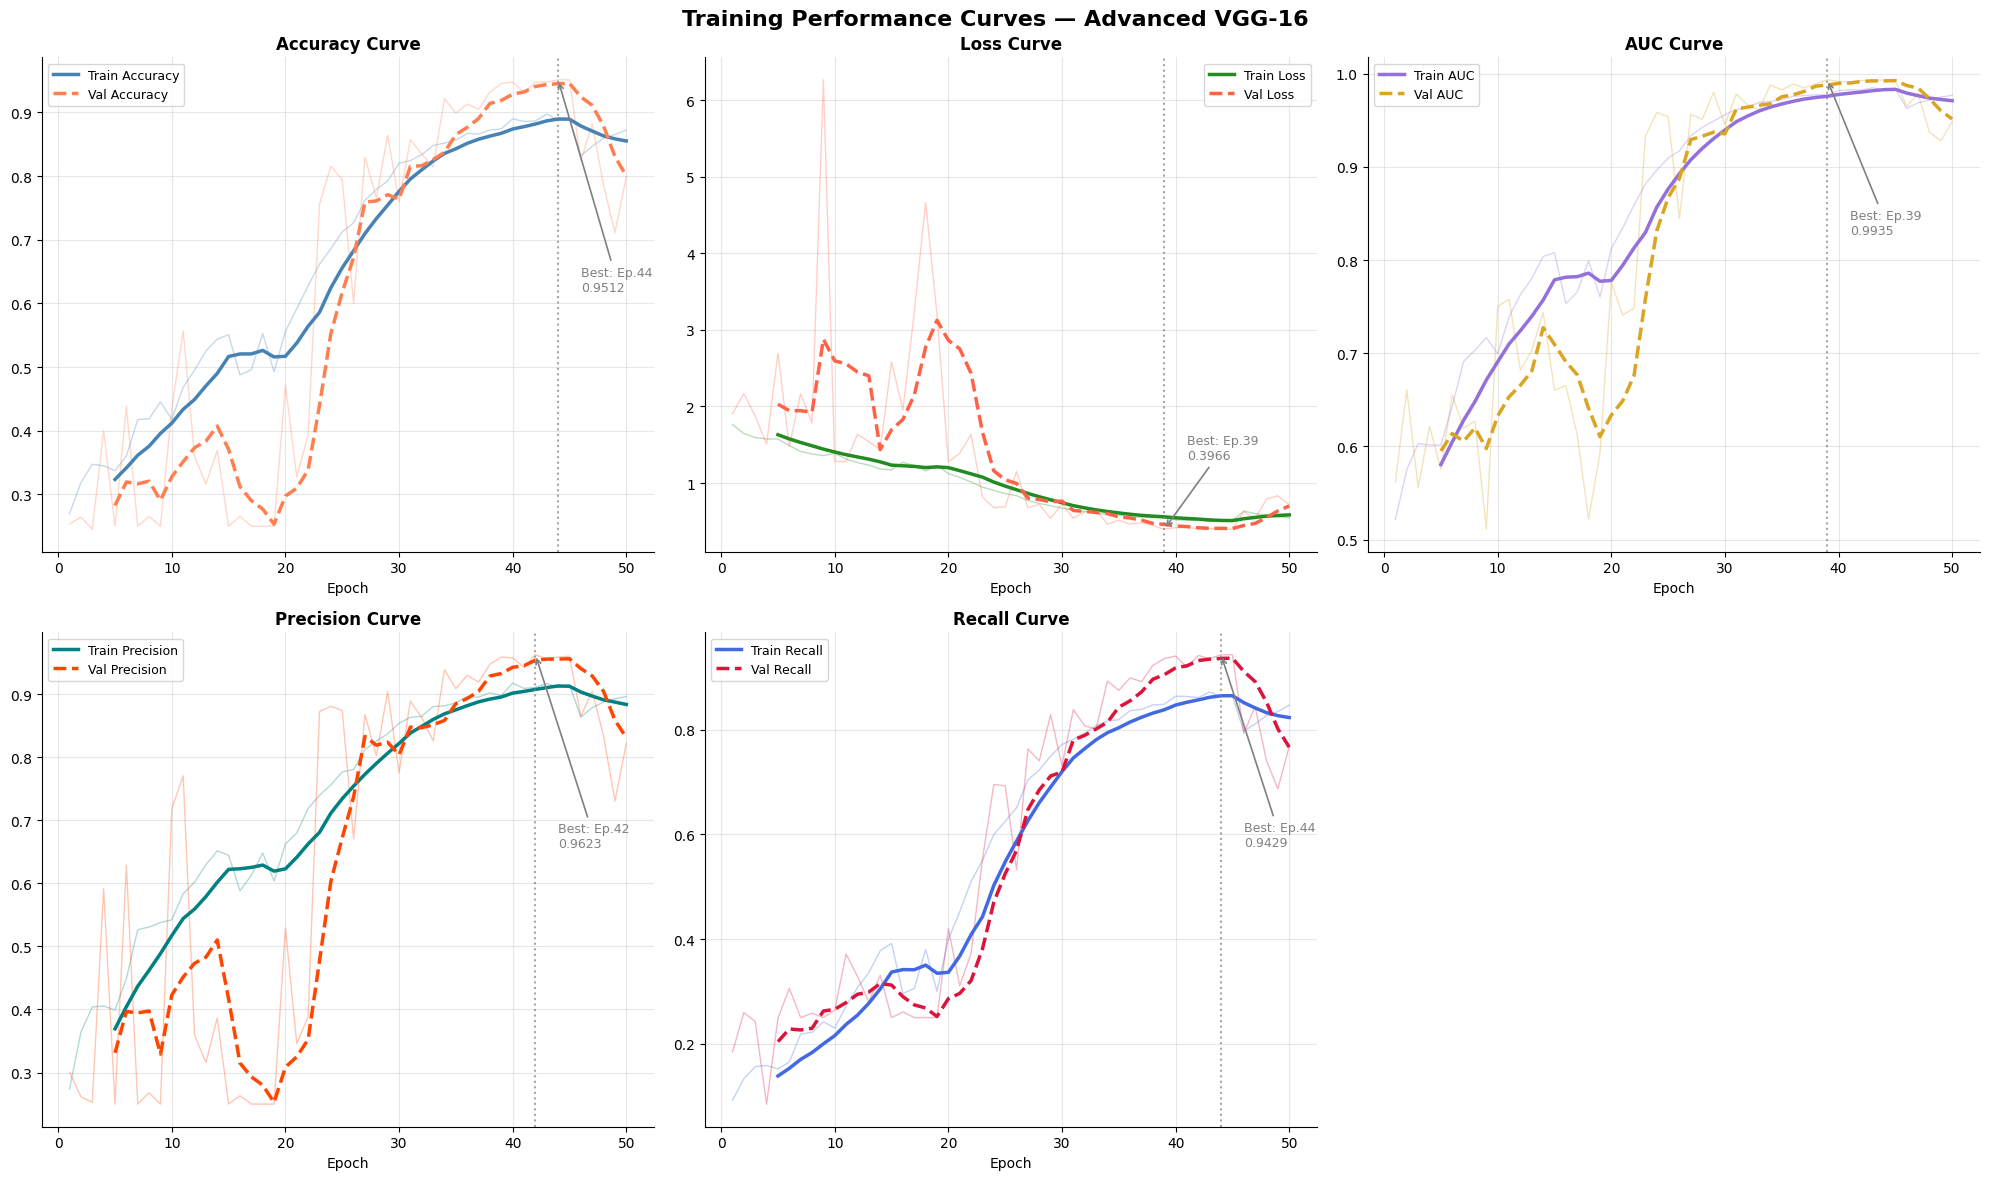

In [ ]:
def plot_training_history(history: dict, save_path: str = None):
    """Comprehensive training curves with moving average."""
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('Training Performance Curves — Advanced VGG-16',
                 fontsize=16, fontweight='bold')

    metrics = [
        ('accuracy',  'val_accuracy',  'Accuracy',  'steelblue',    'coral'),
        ('loss',      'val_loss',      'Loss',      'forestgreen',  'tomato'),
        ('auc',       'val_auc',       'AUC',       'mediumpurple', 'goldenrod'),
        ('precision', 'val_precision', 'Precision', 'teal',         'orangered'),
        ('recall',    'val_recall',    'Recall',    'royalblue',    'crimson'),
    ]

    def moving_avg(x, w=5):
        return np.convolve(x, np.ones(w)/w, mode='valid')

    for ax, (tr_key, val_key, name, tc, vc) in zip(axes.flat, metrics):
        if tr_key not in history:
            ax.set_visible(False)
            continue
        tr = history[tr_key]
        vl = history.get(val_key, [])
        epochs_range = range(1, len(tr) + 1)

        ax.plot(epochs_range, tr, color=tc, alpha=0.3, linewidth=1)
        ax.plot(epochs_range, vl, color=vc, alpha=0.3, linewidth=1)

        if len(tr) >= 5:
            ax.plot(range(5, len(tr)+1), moving_avg(tr),
                    color=tc, linewidth=2.5, label=f'Train {name}')
        if len(vl) >= 5:
            ax.plot(range(5, len(vl)+1), moving_avg(vl),
                    color=vc, linewidth=2.5, linestyle='--', label=f'Val {name}')

        best_epoch = (np.argmin(vl) if 'loss' in tr_key else np.argmax(vl)) + 1 if vl else 1
        if vl:
            ax.axvline(best_epoch, color='gray', linestyle=':', alpha=0.7)
            ax.annotate(f'Best: Ep.{best_epoch}\n{vl[best_epoch-1]:.4f}',
                        xy=(best_epoch, vl[best_epoch-1]),
                        xytext=(best_epoch + 2, np.mean(vl)),
                        fontsize=9, color='gray',
                        arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))

        ax.set_title(f'{name} Curve', fontsize=12, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes.flat[-1].set_visible(False)  # hide unused 6th subplot
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_training_history(
    combined_history,
    save_path=f"{CFG.OUTPUT_DIR}/training_curves_vgg16.png"
)

## 🧪 Cell 15: Comprehensive Model Evaluation

In [ ]:
# Load best saved model
best_model = tf.keras.models.load_model(
    CFG.MODEL_PATH,
    custom_objects={'AdamW': AdamW}
)

# Predict on test set
y_true, y_pred_probs = [], []
class_to_idx = {c: i for i, c in enumerate(CFG.CLASSES)}

for X_batch, y_batch in tqdm(test_gen, desc='Predicting'):
    preds = best_model.predict(X_batch, verbose=0)
    y_pred_probs.extend(preds)
    y_true.extend(np.argmax(y_batch, axis=1))

y_true       = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred       = np.argmax(y_pred_probs, axis=1)

# ── Metrics ──
print('\n' + '='*60)
print('       CLASSIFICATION REPORT — VGG-16')
print('='*60)
print(classification_report(y_true, y_pred,
                              target_names=CFG.CLASSES, digits=4))

# Per-class AUC (one-vs-rest)
y_true_bin = label_binarize(y_true, classes=range(CFG.NUM_CLASSES))
print('Per-class AUC (OvR):')
for i, cls in enumerate(CFG.CLASSES):
    auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
    print(f'  {cls:15s}: {auc:.4f}')

macro_auc = roc_auc_score(y_true_bin, y_pred_probs, average='macro')
print(f'  {"Macro AUC":15s}: {macro_auc:.4f}')

Predicting:   0%|          | 0/100 [00:00<?, ?it/s]

2026-10-04 08:48:37.273491: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-10-04 08:48:42.719046: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),


       CLASSIFICATION REPORT — VGG-16
              precision    recall  f1-score   support

      glioma     0.9417    0.8075    0.8694       400
  meningioma     0.8785    0.8675    0.8730       400
     notumor     0.9106    0.9925    0.9498       400
   pituitary     0.9225    0.9825    0.9516       400

    accuracy                         0.9125      1600
   macro avg     0.9133    0.9125    0.9109      1600
weighted avg     0.9133    0.9125    0.9109      1600

Per-class AUC (OvR):
  glioma         : 0.9528
  meningioma     : 0.9773
  notumor        : 0.9968
  pituitary      : 0.9964
  Macro AUC      : 0.9808


## 🗺️ Cell 16: Confusion Matrix

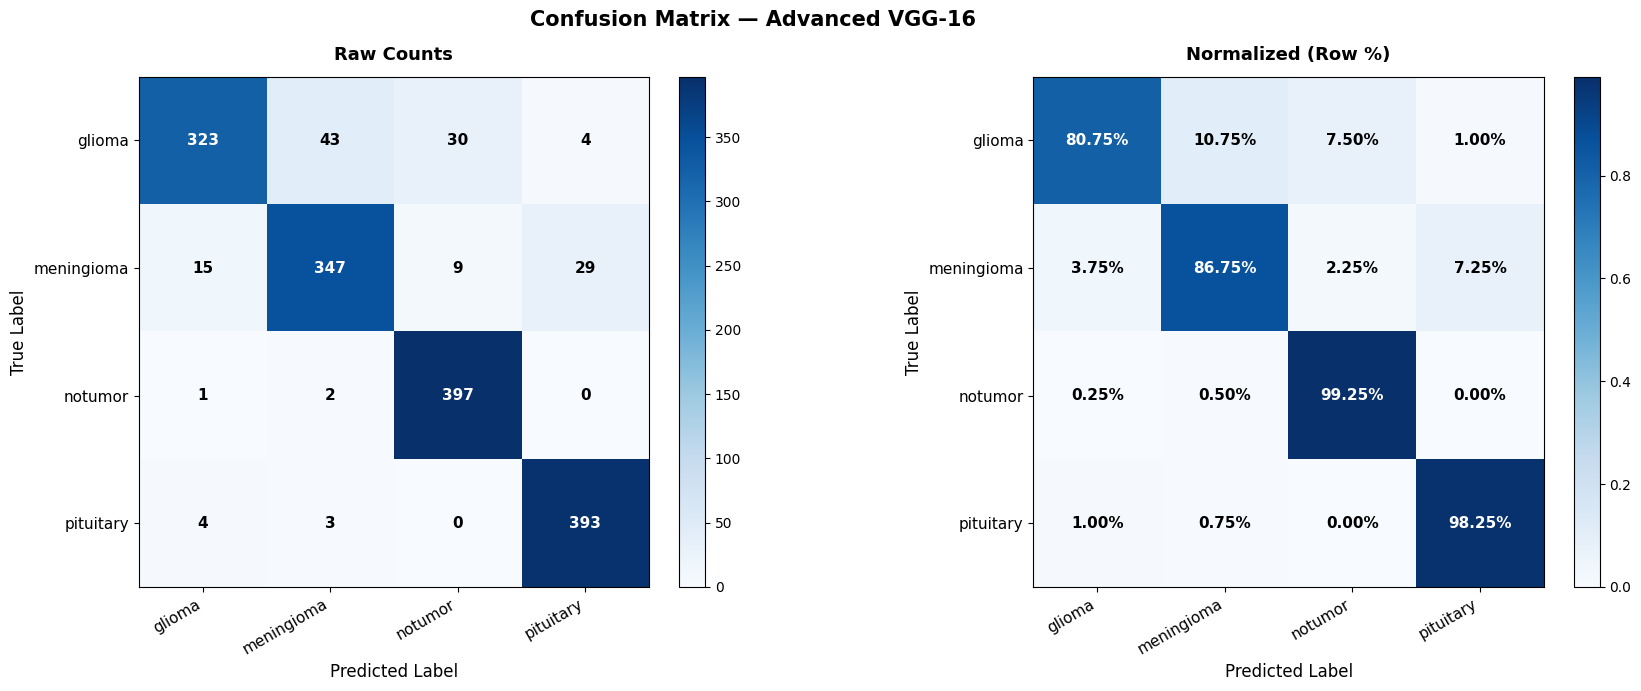

In [ ]:
def plot_confusion_matrix(y_true, y_pred, classes: list, save_path: str = None):
    """Beautiful confusion matrix with raw counts and percentages."""
    cm            = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('Confusion Matrix — Advanced VGG-16',
                 fontsize=15, fontweight='bold')

    for ax, data, title, fmt in zip(
        axes,
        [cm, cm_normalized],
        ['Raw Counts', 'Normalized (Row %)'],
        ['d', '.2%']
    ):
        im = ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        tick_marks = np.arange(len(classes))
        ax.set_xticks(tick_marks)
        ax.set_yticks(tick_marks)
        ax.set_xticklabels(classes, rotation=30, ha='right', fontsize=11)
        ax.set_yticklabels(classes, fontsize=11)

        thresh = data.max() / 2.0
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val   = data[i, j]
                color = 'white' if val > thresh else 'black'
                ax.text(j, i, format(val, fmt), ha='center', va='center',
                        color=color, fontsize=11, fontweight='bold')

        ax.set_ylabel('True Label', fontsize=12)
        ax.set_xlabel('Predicted Label', fontsize=12)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_confusion_matrix(
    y_true, y_pred, CFG.CLASSES,
    save_path=f"{CFG.OUTPUT_DIR}/confusion_matrix_vgg16.png"
)

## 📉 Cell 17: ROC Curves & Precision-Recall Curves

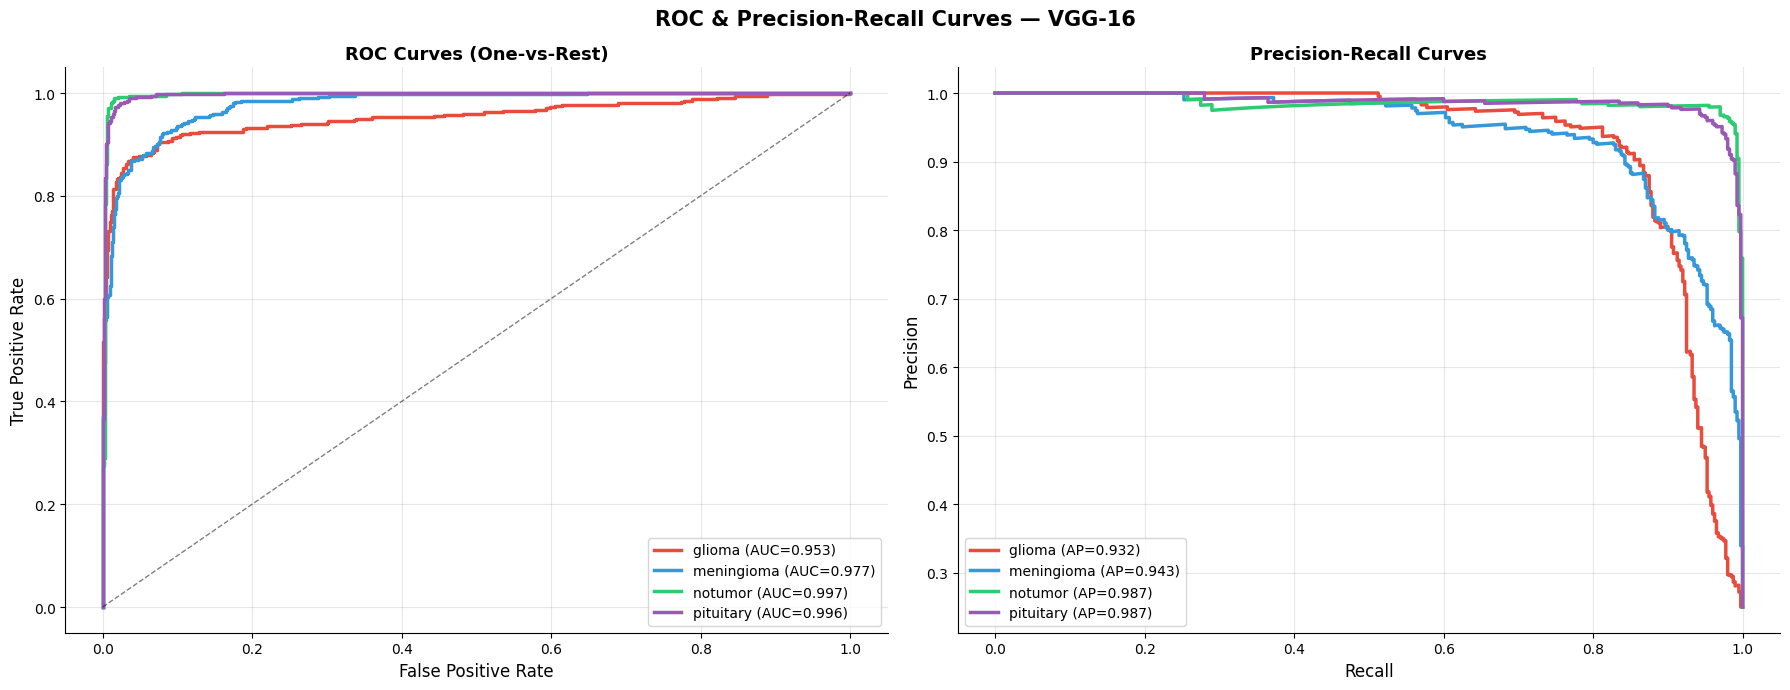

In [ ]:
def plot_roc_pr_curves(y_true_bin, y_pred_probs, classes: list, save_path: str = None):
    """Multi-class ROC and PR curves with AUC scores."""
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('ROC & Precision-Recall Curves — VGG-16',
                 fontsize=15, fontweight='bold')

    # ── ROC Curves ──
    ax = axes[0]
    for i, (cls, color) in enumerate(zip(classes, colors)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
        ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{cls} (AUC={auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5)
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('ROC Curves (One-vs-Rest)', fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # ── PR Curves ──
    ax = axes[1]
    for i, (cls, color) in enumerate(zip(classes, colors)):
        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, i], y_pred_probs[:, i]
        )
        ap = average_precision_score(y_true_bin[:, i], y_pred_probs[:, i])
        ax.plot(recall, precision, color=color, linewidth=2.5,
                label=f'{cls} (AP={ap:.3f})')
    ax.set_xlabel('Recall', fontsize=12)
    ax.set_ylabel('Precision', fontsize=12)
    ax.set_title('Precision-Recall Curves', fontsize=13, fontweight='bold')
    ax.legend(loc='lower left', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_roc_pr_curves(
    y_true_bin, y_pred_probs, CFG.CLASSES,
    save_path=f"{CFG.OUTPUT_DIR}/roc_pr_curves_vgg16.png"
)

In [ ]:
# ── Save test-set predictions for statistical comparison ──
# Tags: 'VGG16_SE' (proposed), 'VGG16_noSE', 'VGG16_noImageNet',
#       'MobileNetV2', 'InceptionV3', 'DenseNet121', 'ResNet50'
MODEL_TAG = 'VGG16_noImageNet'                 # <-- change in each notebook
PRED_DIR  = f'{CFG.OUTPUT_DIR}/preds'
os.makedirs(PRED_DIR, exist_ok=True)

path_col = next(c for c in test_df.columns if c != 'label')   # image-path column
np.savez(f'{PRED_DIR}/{MODEL_TAG}.npz',
         y_true=y_true, y_pred=y_pred, y_prob=y_pred_probs,
         paths=test_df[path_col].astype(str).values)
print(f"✅ Saved {PRED_DIR}/{MODEL_TAG}.npz | n={len(y_true)}, acc={np.mean(y_true==y_pred):.4f}")

✅ Saved /kaggle/working/outputs_ablation_noImagenet/preds/VGG16_noImageNet.npz | n=1600, acc=0.9125


In [ ]:
import time, os, json, glob, platform
import numpy as np, tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

# tag → saved best-model path. Add all models here to time them in ONE session.
MODELS = {
    'VGG16_noImageNet': CFG.MODEL_PATH,
    # 'VGG16_SE'   : glob.glob('/kaggle/input/**/best_vgg16_model.h5', recursive=True)[0],
    # 'MobileNetV2': '/kaggle/input/<notebook-output>/.../best_model.h5',
}
N_WARMUP, N_RUNS = 50, 300                   # batch size = 1
OUT_DIR = f'{CFG.OUTPUT_DIR}/preds'
os.makedirs(OUT_DIR, exist_ok=True)

def count_gflops(m):
    shape = (1,) + tuple(m.input_shape[1:])
    conc = tf.function(lambda x: m(x, training=False)).get_concrete_function(
        tf.TensorSpec(shape, tf.float32))
    _, graph_def = convert_variables_to_constants_v2_as_graph(conc)
    with tf.Graph().as_default() as g:
        tf.graph_util.import_graph_def(graph_def, name='')
        prof = tf.compat.v1.profiler.profile(
            graph=g, run_meta=tf.compat.v1.RunMetadata(), cmd='op',
            options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation())
    return prof.total_float_ops / 1e9

def latency_ms(path, device):
    with tf.device(device):                          # model rebuilt on the target device
        m = tf.keras.models.load_model(path, compile=False)
        x = tf.random.uniform((1,) + tuple(m.input_shape[1:]))
        f = tf.function(lambda t: m(t, training=False))
        for _ in range(N_WARMUP):
            f(x).numpy()
        t = []
        for _ in range(N_RUNS):
            t0 = time.perf_counter()
            f(x).numpy()                             # .numpy() forces GPU sync
            t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return dict(mean=t.mean(), std=t.std(), median=np.median(t))

gpus     = tf.config.list_physical_devices('GPU')
gpu_name = tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'GPU') if gpus else None
cpu_desc = f"{platform.processor() or platform.machine()} ({os.cpu_count()} logical cores)"

all_res = []
for tag, path in MODELS.items():
    m = tf.keras.models.load_model(path, compile=False)
    r = dict(model=tag, input=tuple(m.input_shape[1:3]),
             params_M=m.count_params()/1e6, gflops=count_gflops(m))
    r['gmacs']   = r['gflops'] / 2
    r['gpu_ms']  = latency_ms(path, '/GPU:0') if gpus else None
    r['cpu_ms']  = latency_ms(path, '/CPU:0')
    all_res.append(r)
    del m; tf.keras.backend.clear_session()

summary = pd.DataFrame([{
    'Model'       : r['model'],
    'Input'       : f"{r['input'][0]}×{r['input'][1]}",
    'Params (M)'  : f"{r['params_M']:.2f}",
    'GFLOPs'      : f"{r['gflops']:.2f}",
    'GMACs'       : f"{r['gmacs']:.2f}",
    'GPU (ms/img)': f"{r['gpu_ms']['mean']:.2f} ± {r['gpu_ms']['std']:.2f}" if r['gpu_ms'] else 'n/a',
    'CPU (ms/img)': f"{r['cpu_ms']['mean']:.2f} ± {r['cpu_ms']['std']:.2f}",
} for r in all_res])
print(f"GPU: {gpu_name} | CPU: {cpu_desc}\n")
print(summary.to_string(index=False))

summary.to_csv(f'{OUT_DIR}/complexity_summary.csv', index=False)
json.dump(all_res, open(f'{OUT_DIR}/complexity.json', 'w'), indent=2, default=float)

I0000 00:00:1791104045.766144      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791104045.767188      49 single_machine.cc:376] Starting new session
I0000 00:00:1791104045.782742      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791104045.784430      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation kernel type, such as MatMul, Conv2D. Graph nodes belonging to the same type are aggregated together.
flops: Number of float operations. Note: Please read the implementation for th

## 📋 Cell 26: Research Summary Report

In [ ]:
report = f"""
╔══════════════════════════════════════════════════════════════════════════╗
║       RESEARCH SUMMARY — ADVANCED BRAIN TUMOR DETECTION                 ║
║       VGG-16 with Advanced Preprocessing & Explainability               ║
╠══════════════════════════════════════════════════════════════════════════╣
║                                                                          ║
║  DATASET                                                                 ║
║  ─────────────────────────────────────────────────────────               ║
║  • Source   : Kaggle Brain Tumor MRI Dataset (Masoud Nickparvar)        ║
║  • Total    : ~7,023 MRI images (4-class)                               ║
║  • Classes  : Glioma | Meningioma | Pituitary | No Tumor                ║
║  • Split    : 70% train / 15% val / 15% test (stratified)               ║
║  • CV       : 5-fold stratified cross-validation                        ║
║                                                                          ║
║  PREPROCESSING INNOVATIONS                                               ║
║  ─────────────────────────────────────────────────────────               ║
║  • Skull-stripping proxy (Otsu + morphological operations)              ║
║  • Smart ROI crop (tight brain bounding box + 5% padding)               ║
║  • CLAHE (clip=3.0, tile=8x8) for local contrast enhancement            ║
║  • Gamma correction (γ=1.1)                                             ║
║  • Gaussian denoising (σ=1)                                             ║
║  • Per-image intensity normalization [0, 1]                             ║
║                                                                          ║
║  MODEL ARCHITECTURE                                                      ║
║  ─────────────────────────────────────────────────────────               ║
║  • Backbone : VGG-16 (RANDOM INIT, no ImageNet, include_top=False)      ║
║  • Features : 7x7x512 from block5_conv3                                 ║
║  • Attention: SE block (512 → 64 → 512 channel recalibration)           ║
║  • Pooling  : GAP + GMP concatenated → 1024-dim vector                  ║
║  • Head     : Dense(512) → BN → ReLU → Drop(0.5)                       ║
║               → Dense(256) → BN → ReLU → Drop(0.3)                     ║
║               → Dense(4, softmax)                                       ║
║                                                                          ║
║  TRAINING STRATEGY                                                       ║
║  ─────────────────────────────────────────────────────────               ║
║  • Phase 1  : Full net from scratch (Adam lr=1e-3, 15 epochs)           ║
║  • Phase 2  : All layers trainable (AdamW lr=1e-5, wd=1e-4)             ║
║  • Schedule : Cosine annealing with warm restarts (T_max=30)            ║
║  • Smooth   : Label smoothing ε=0.05                                    ║
║  • Augment  : Albumentations (flip, rotate, elastic, CLAHE, dropout)   ║
║                                                                          ║
║  EXPLAINABILITY                                                          ║
║  ─────────────────────────────────────────────────────────               ║
║  • GradCAM      : block5_conv3 (14x14 spatial, rich semantics)         ║
║  • GradCAM++    : Improved spatial coverage                             ║
║  • LIME         : Superpixel-based local explanations                   ║
║  • SHAP         : DeepExplainer in isolated subprocess                  ║
║                                                                          ║
║  FINAL RESULTS                                                           ║
║  ─────────────────────────────────────────────────────────               ║
║  • Test Accuracy : (see dashboard)                                      ║
║  • Macro F1      : (see dashboard)                                      ║
║  • Macro AUC     : (see dashboard)                                      ║
║  • CV Mean Acc   : {cv_results['accuracy'].mean():.4f} ± {cv_results['accuracy'].std():.4f}         ║
║                                                                          ║
╚══════════════════════════════════════════════════════════════════════════╝
"""
print(report)

with open(f"{CFG.OUTPUT_DIR}/research_summary_vgg16.txt", 'w') as f:
    f.write(report)
print(f"✅ Summary saved to {CFG.OUTPUT_DIR}/research_summary_vgg16.txt")